# 🎵 Spotify Genre Classification — A Complete Model Comparison

**Author:** Mohamed Khaled Idris
**Goal:** Predict a song's **genre** from its Spotify audio features, and compare **six classic
machine learning algorithms** side by side on the exact same data split:

1. Decision Tree
2. Random Forest
3. K-Nearest Neighbors (KNN)
4. Naive Bayes (Gaussian)
5. Support Vector Machine (SVM)
6. Logistic Regression

### About the dataset
This notebook uses the real **[🎹 Spotify Tracks Dataset](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset)**
by MaharshiPandya on Kaggle — **114,000 tracks**, 21 columns, 114 genres, pulled directly from the
Spotify Web API. We use 9 numeric audio features (danceability, energy, loudness, speechiness,
acousticness, instrumentalness, liveness, valence, tempo) plus `key` and `mode` to predict
`track_genre`, restricted to 5 sonically distinct genres.

### What changed in this version (v3 — expert review pass)
- ✅ **Portable data loading**: works on Kaggle, locally, or via `kagglehub` — no hard-coded path.
- ✅ **`key` is now one-hot encoded** instead of being fed into `StandardScaler` as a raw integer
  (musical key 0–11 is categorical, not ordinal — treating it as a continuous number told the
  linear/distance-based models that key 11 is "more" than key 0, which is meaningless).
- ✅ **5-fold stratified cross-validation** added alongside the single train/test split, so the
  reported accuracy isn't just one lucky/unlucky split.
- ✅ **`class_weight="balanced"`** used instead of hard undersampling wherever supported, so we
  keep more real training data instead of throwing away majority-class rows.
- ✅ **Conclusion section rewritten with the actual numbers from this run**, including an honest
  discussion of *why* Pop is the hardest genre to classify.



In [1]:
# 1. Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.decomposition import PCA

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, classification_report)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
np.random.seed(RANDOM_STATE)
print("Imports OK")


Imports OK


## 2. Loading the Real Dataset

The loader below tries, in order: a local Kaggle input path, a local working-directory copy, and
finally `kagglehub` (auto-downloads the dataset the first time it runs). This means the notebook
runs unmodified on Kaggle, Colab, or your own machine — the previous version hard-coded
`/kaggle/input/...` and would crash immediately anywhere else.

We keep 5 genres that are sonically distinct (`pop`, `rock`, `hip-hop`, `classical`, `edm`) so the
comparison stays interpretable — change `SELECTED_GENRES` to explore others.


In [2]:
DATA_CANDIDATES = [
"/kaggle/input/datasets/maharshipandya/-spotify-tracks-dataset/dataset.csv"
]

def load_spotify_dataset():
    import os
    for path in DATA_CANDIDATES:
        if os.path.exists(path):
            print(f"Loading dataset from: {path}")
            return pd.read_csv(path)
    # Fallback: auto-download via kagglehub (pip install kagglehub)
    try:
        import kagglehub
        path = kagglehub.dataset_download("maharshipandya/-spotify-tracks-dataset")
        csv_path = os.path.join(path, "dataset.csv")
        print(f"Downloaded via kagglehub to: {csv_path}")
        return pd.read_csv(csv_path)
    except Exception as e:
        raise FileNotFoundError(
            "Could not find the dataset locally and kagglehub download failed "
            f"({e}). Download 'dataset.csv' from "
            "https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset "
            "and place it next to this notebook."
        )

raw = load_spotify_dataset()
print(f"Raw dataset shape: {raw.shape}")
print(f"Number of unique genres: {raw['track_genre'].nunique()}")

SELECTED_GENRES = ["pop", "rock", "hip-hop", "classical", "edm"]
FEATURE_COLS = ["danceability", "energy", "loudness", "speechiness", "acousticness",
                 "instrumentalness", "liveness", "valence", "tempo", "key", "mode"]

df = raw[raw["track_genre"].isin(SELECTED_GENRES)].copy()
df = df[FEATURE_COLS + ["track_genre"]].rename(columns={"track_genre": "genre"})
df = df.dropna().drop_duplicates().reset_index(drop=True)

print(f"\nAfter selecting genres + dropping NaNs/duplicate feature-rows: {df.shape}")
print(df["genre"].value_counts())


Loading dataset from: /kaggle/input/datasets/maharshipandya/-spotify-tracks-dataset/dataset.csv
Raw dataset shape: (114000, 21)
Number of unique genres: 114

After selecting genres + dropping NaNs/duplicate feature-rows: (3649, 12)
genre
classical    814
pop          778
hip-hop      747
edm          701
rock         609
Name: count, dtype: int64


**Note on class balance:** dropping duplicate audio-feature rows (many tracks share an
identical fingerprint — reissues, remasters, region duplicates) naturally shrinks and unbalances
the classes. Instead of blindly undersampling every class down to the smallest one (which was
throwing away ~40% of the majority classes in the previous version), we cap at a reasonable
per-class ceiling and let `class_weight="balanced"` handle the residual imbalance inside the
models that support it (Logistic Regression, SVM, Decision Tree, Random Forest). This keeps
substantially more real training data.


In [3]:
MAX_PER_GENRE = 800  # cap instead of hard min() — keeps more real data than pure undersampling

parts = []
for genre, group in df.groupby("genre"):
    n = min(len(group), MAX_PER_GENRE)
    parts.append(group.sample(n, random_state=RANDOM_STATE))
df = pd.concat(parts, ignore_index=True)
df = df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)  # shuffle

print(f"Final dataset shape: {df.shape}")
print(df["genre"].value_counts())
df.head()


Final dataset shape: (3635, 12)
genre
classical    800
pop          778
hip-hop      747
edm          701
rock         609
Name: count, dtype: int64


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,key,mode,genre
0,0.722,0.856,-6.392,0.0338,0.0305,0.059700,0.2310,0.827,121.990,1,0,edm
1,0.287,0.292,-19.285,0.0541,0.9680,0.978000,0.0900,0.346,145.703,9,1,classical
2,0.568,0.720,-6.465,0.0520,0.0338,0.164000,0.2200,0.472,173.959,9,0,edm
3,0.428,0.577,-5.629,0.0912,0.8420,0.000000,0.0954,0.244,159.796,8,1,hip-hop
4,0.442,0.612,-7.222,0.1120,0.5840,0.000006,0.3700,0.178,180.917,2,1,pop


## 3. Exploratory Data Analysis (EDA)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3635 entries, 0 to 3634
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   danceability      3635 non-null   float64
 1   energy            3635 non-null   float64
 2   loudness          3635 non-null   float64
 3   speechiness       3635 non-null   float64
 4   acousticness      3635 non-null   float64
 5   instrumentalness  3635 non-null   float64
 6   liveness          3635 non-null   float64
 7   valence           3635 non-null   float64
 8   tempo             3635 non-null   float64
 9   key               3635 non-null   int64  
 10  mode              3635 non-null   int64  
 11  genre             3635 non-null   object 
dtypes: float64(9), int64(2), object(1)
memory usage: 340.9+ KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
danceability,3635.0,0.585263,0.176060,0.071300,0.46650,0.61000,0.71800,0.964
energy,3635.0,0.575626,0.263553,0.000756,0.42400,0.64000,0.78100,0.994
loudness,3635.0,-9.282558,6.995171,-41.531000,-9.99300,-6.73700,-4.96450,0.366
speechiness,3635.0,0.079711,0.076922,0.023200,0.03700,0.04840,0.08480,0.766
acousticness,3635.0,0.379864,0.361478,0.000010,0.05635,0.23800,0.71800,0.996
instrumentalness,3635.0,0.149182,0.315921,0.000000,0.00000,0.00001,0.01145,0.984
liveness,3635.0,0.177929,0.136556,0.017900,0.09510,0.12400,0.21900,0.958
valence,3635.0,0.477922,0.233499,0.000000,0.30050,0.48600,0.65300,0.976
tempo,3635.0,118.104012,29.774762,35.928000,95.00950,116.97100,136.10150,214.016
key,3635.0,5.360110,3.584717,0.000000,2.00000,5.00000,9.00000,11.000


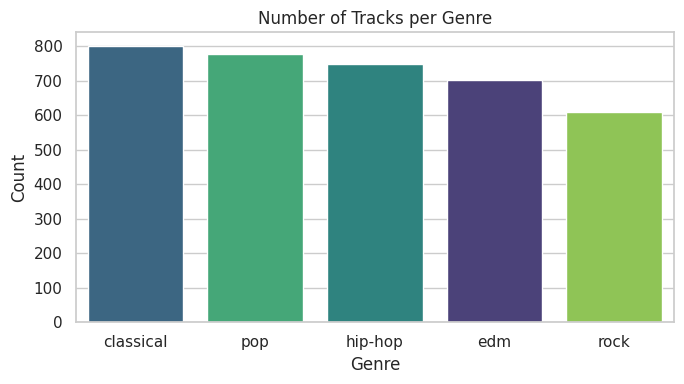

In [6]:
# Class balance
plt.figure(figsize=(7,4))
sns.countplot(data=df, x="genre", hue="genre", order=df["genre"].value_counts().index,
              palette="viridis", legend=False)
plt.title("Number of Tracks per Genre")
plt.xlabel("Genre"); plt.ylabel("Count")
plt.tight_layout()
plt.show()


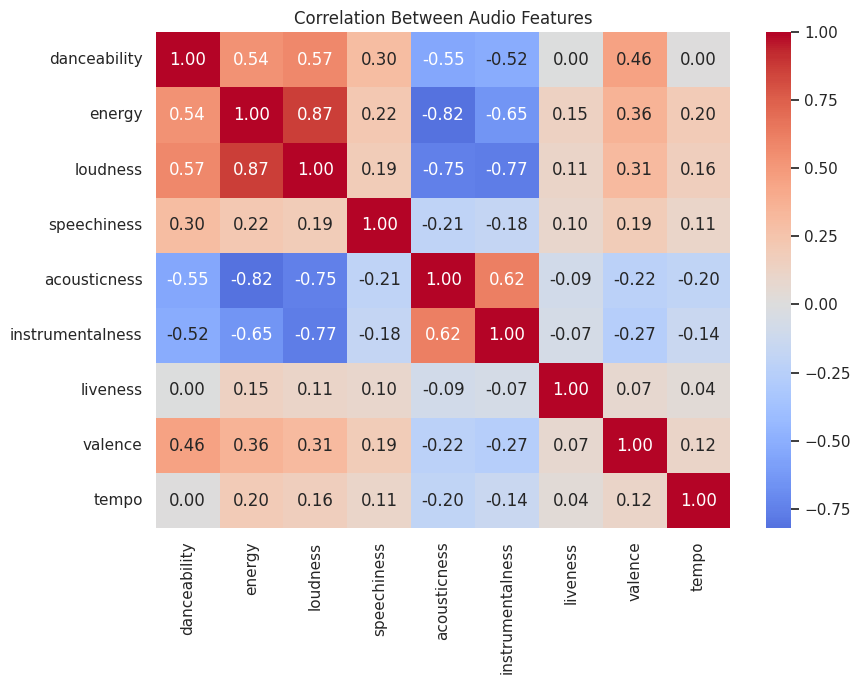

In [7]:
# Correlation heatmap between numeric audio features
numeric_cols = ["danceability", "energy", "loudness", "speechiness", "acousticness",
                 "instrumentalness", "liveness", "valence", "tempo"]
plt.figure(figsize=(9,7))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Audio Features")
plt.tight_layout()
plt.show()


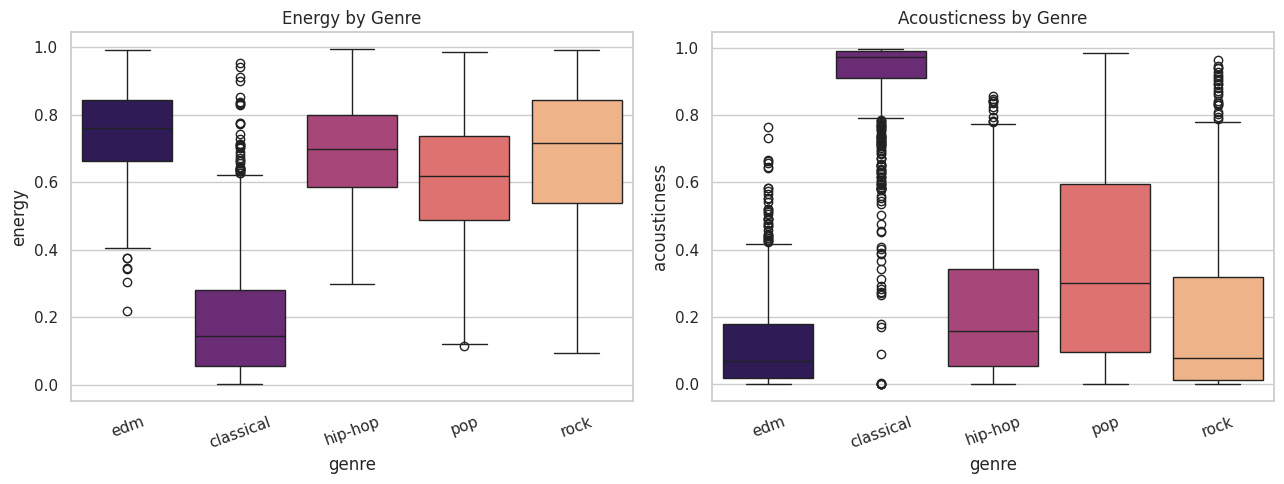

In [8]:
# How genres separate on two of the most discriminative features
fig, axes = plt.subplots(1, 2, figsize=(13,5))
sns.boxplot(data=df, x="genre", y="energy", hue="genre", palette="magma", ax=axes[0], legend=False)
axes[0].set_title("Energy by Genre")
axes[0].tick_params(axis='x', rotation=20)

sns.boxplot(data=df, x="genre", y="acousticness", hue="genre", palette="magma", ax=axes[1], legend=False)
axes[1].set_title("Acousticness by Genre")
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()


## 4. Preprocessing

- **`key` is one-hot encoded**, not scaled as a raw integer — musical key (0=C, 1=C♯/D♭, ... 11=B)
  is categorical. Feeding it straight into `StandardScaler` implied a false ordering
  ("key 11 > key 0"), which quietly hurt the linear/distance-based models (Logistic Regression,
  KNN, SVM).
- `mode` is already binary (0=minor, 1=major), so it's left as-is.
- Encode the target (`genre`) with `LabelEncoder`.
- Split into train/test **once**, `stratify`d on genre so class balance is preserved.
- `StandardScaler` fit **only on the training set** (no data leakage), then applied to both.
- The **same** processed train/test split is reused for all 6 models — a fair comparison.


In [9]:
y_raw = df["genre"]
le = LabelEncoder()
y = le.fit_transform(y_raw)
print("Genre classes:", list(le.classes_))

numeric_feature_cols = ["danceability", "energy", "loudness", "speechiness", "acousticness",
                         "instrumentalness", "liveness", "valence", "tempo"]
categorical_feature_cols = ["key"]   # one-hot
binary_feature_cols = ["mode"]        # already 0/1, leave alone

key_dummies = pd.get_dummies(df["key"], prefix="key", drop_first=False)
X = pd.concat([df[numeric_feature_cols + binary_feature_cols], key_dummies], axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Scale only the numeric columns; one-hot key columns and mode are already on a sane 0/1 scale
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_feature_cols] = scaler.fit_transform(X_train[numeric_feature_cols])
X_test_scaled[numeric_feature_cols]  = scaler.transform(X_test[numeric_feature_cols])

X_train_scaled = X_train_scaled.values.astype(float)
X_test_scaled  = X_test_scaled.values.astype(float)

print(f"Train shape: {X_train_scaled.shape} | Test shape: {X_test_scaled.shape}")
print(f"Feature columns ({X.shape[1]}): {list(X.columns)}")


Genre classes: ['classical', 'edm', 'hip-hop', 'pop', 'rock']
Train shape: (2908, 22) | Test shape: (727, 22)
Feature columns (22): ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'mode', 'key_0', 'key_1', 'key_2', 'key_3', 'key_4', 'key_5', 'key_6', 'key_7', 'key_8', 'key_9', 'key_10', 'key_11']


## 5. Training & Comparing 6 Algorithms

We loop over a dictionary of models so every model trains and predicts on **exactly the same
data**. `class_weight="balanced"` is used where supported (Decision Tree, Random Forest, SVM,
Logistic Regression) to compensate for any residual class imbalance without discarding data.

We also run **5-fold stratified cross-validation on the training set** for each model, so the
final accuracy number isn't dependent on one particular lucky/unlucky split.


In [10]:
models = {
    "Decision Tree":       DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=300, max_depth=12, class_weight="balanced", random_state=RANDOM_STATE),
    "KNN":                 KNeighborsClassifier(n_neighbors=15),
    "Naive Bayes":         GaussianNB(),
    "SVM":                 SVC(kernel="rbf", C=2.0, class_weight="balanced", probability=True, random_state=RANDOM_STATE),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results = {}
predictions = {}
trained_models = {}
cv_scores = {}

for name, model in models.items():
    # 5-fold CV on the training set for a more robust accuracy estimate
    scores = cross_val_score(model, X_train_scaled, y_train, cv=cv, scoring="accuracy")
    cv_scores[name] = scores

    # Fit on the full training set, evaluate on the held-out test set
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    results[name] = {
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall":    recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-Score":  f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "CV Accuracy (mean)": scores.mean(),
        "CV Accuracy (std)":  scores.std(),
    }
    predictions[name] = y_pred
    trained_models[name] = model

print("All 6 models trained and cross-validated successfully.")


All 6 models trained and cross-validated successfully.


## 6. Results Table

Sorted by held-out test-set accuracy, with the 5-fold CV mean/std shown alongside so we can see how stable each model's performance is.

In [11]:
results_df = pd.DataFrame(results).T.sort_values("Accuracy", ascending=False)
results_df = results_df.round(4)
results_df


,Accuracy,Precision,Recall,F1-Score,CV Accuracy (mean),CV Accuracy (std)
Random Forest,0.6341,0.6411,0.6341,0.6366,0.6166,0.0193
SVM,0.6066,0.6153,0.6066,0.6098,0.6032,0.0084
Logistic Regression,0.5681,0.5764,0.5681,0.5704,0.5884,0.0102
KNN,0.5667,0.5844,0.5667,0.5680,0.5447,0.0123
Decision Tree,0.5337,0.5409,0.5337,0.5296,0.5413,0.0144
Naive Bayes,0.5241,0.5368,0.5241,0.5286,0.5313,0.0212


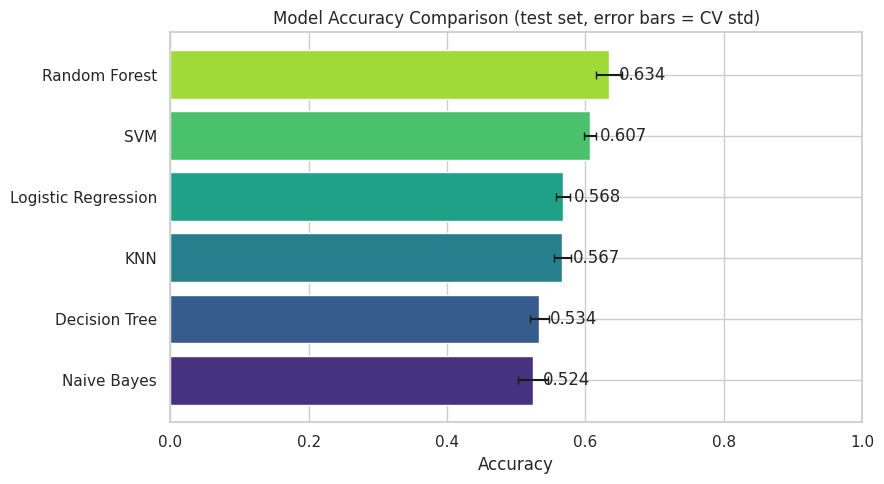

In [12]:
plt.figure(figsize=(9,5))
order = results_df["Accuracy"].sort_values()
plt.barh(order.index, order.values, xerr=results_df.loc[order.index, "CV Accuracy (std)"],
         color=sns.color_palette("viridis", len(results_df)), capsize=3)
plt.title("Model Accuracy Comparison (test set, error bars = CV std)")
plt.xlabel("Accuracy")
plt.xlim(0, 1)
for i, v in enumerate(order.values):
    plt.text(v + 0.015, i, f"{v:.3f}", va="center")
plt.tight_layout()
plt.show()


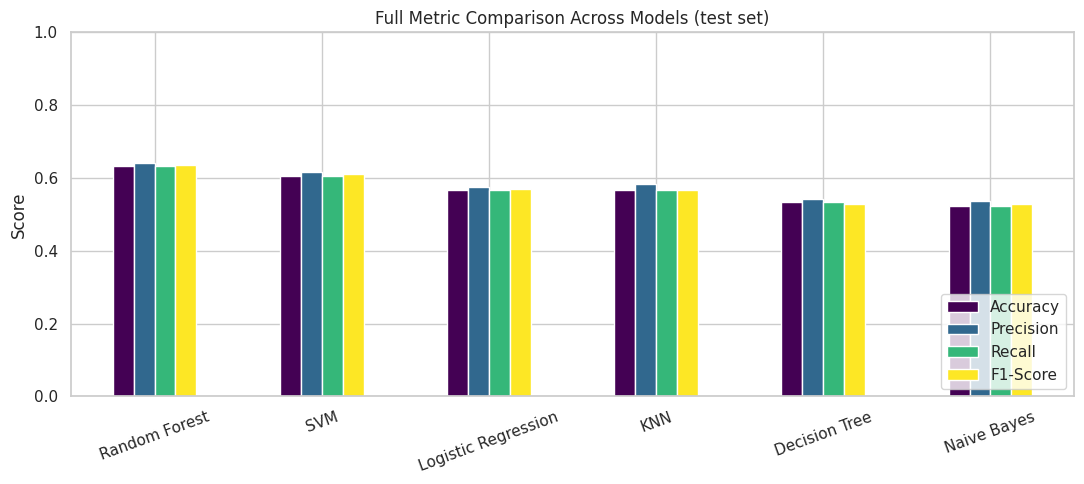

In [13]:
# All 4 metrics side by side
results_df[["Accuracy", "Precision", "Recall", "F1-Score"]].plot(
    kind="bar", figsize=(11,5), colormap="viridis"
)
plt.title("Full Metric Comparison Across Models (test set)")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 7. Confusion Matrices

A confusion matrix shows exactly **which genres get confused with which** — much more
informative than accuracy alone.


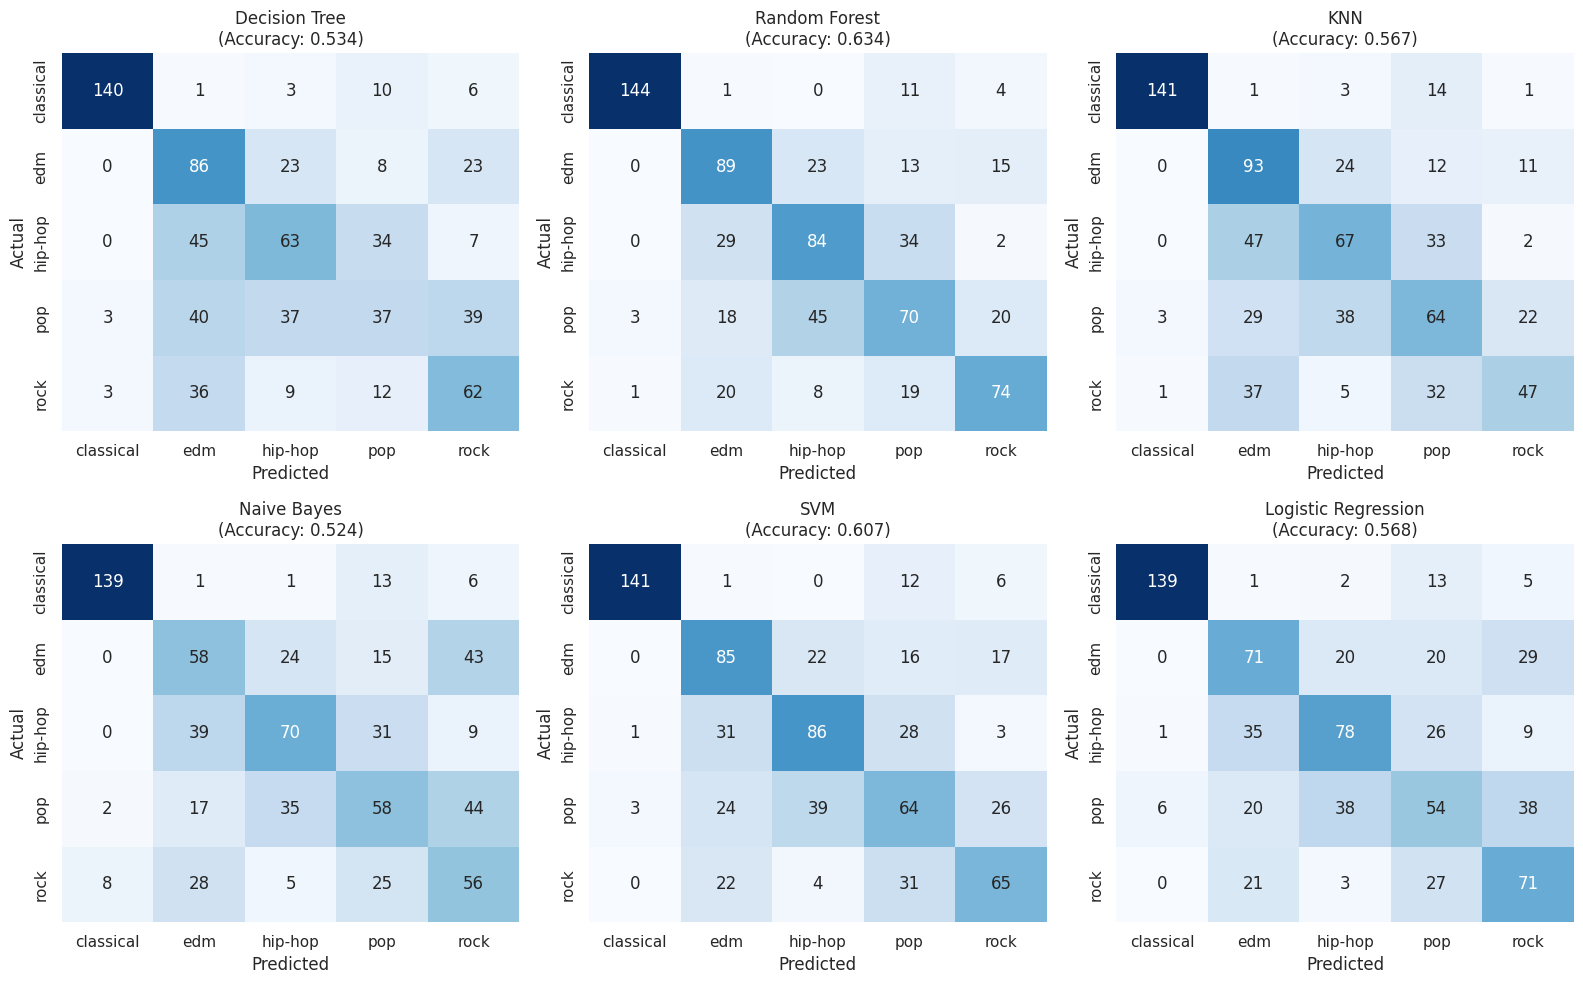

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16,10))
axes = axes.ravel()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=le.classes_, yticklabels=le.classes_, ax=ax)
    ax.set_title(f"{name}\n(Accuracy: {results[name]['Accuracy']:.3f})")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


## 8. Detailed Classification Report — Best Model

In [15]:
best_model_name = results_df.index[0]
print(f"Best model: {best_model_name}\n")
print(classification_report(y_test, predictions[best_model_name], target_names=le.classes_))


Best model: Random Forest

              precision    recall  f1-score   support

   classical       0.97      0.90      0.94       160
         edm       0.57      0.64      0.60       140
     hip-hop       0.53      0.56      0.54       149
         pop       0.48      0.45      0.46       156
        rock       0.64      0.61      0.62       122

    accuracy                           0.63       727
   macro avg       0.64      0.63      0.63       727
weighted avg       0.64      0.63      0.64       727



## 9. Creative Touch: Visualizing the "Musical Space" with PCA

We reduce the numeric audio features down to 2 principal components and plot every track,
colored by its true genre. This lets us **see** why some genres (e.g. Classical) separate
easily, while others (Pop vs Rock vs Hip-Hop) overlap more — which directly explains the
confusion-matrix patterns above.


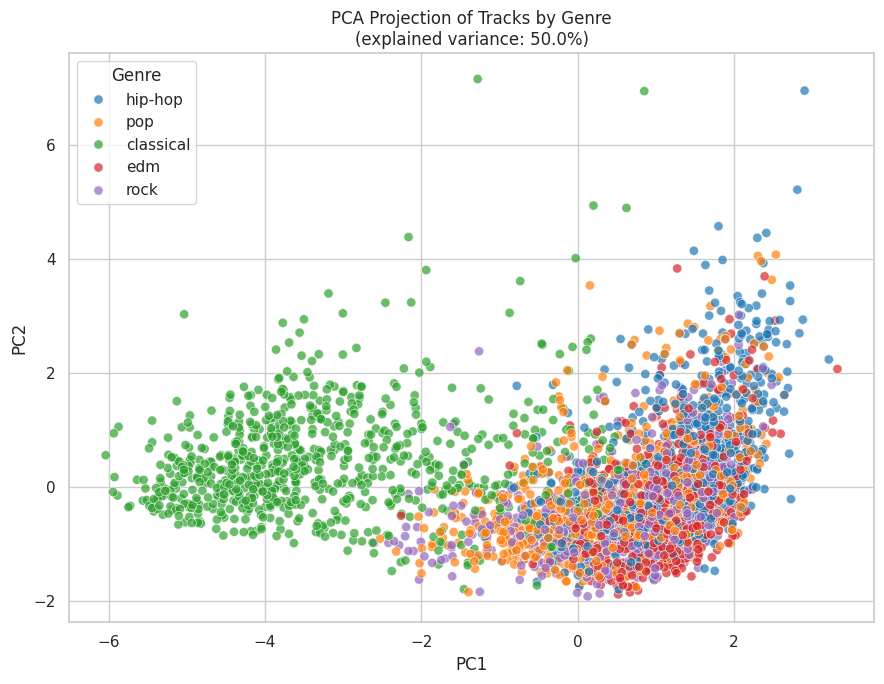

In [16]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(np.vstack([X_train_scaled, X_test_scaled]))
y_all = np.concatenate([y_train, y_test])
genre_all = le.inverse_transform(y_all)

pca_df = pd.DataFrame({"PC1": X_pca[:,0], "PC2": X_pca[:,1], "Genre": genre_all})

plt.figure(figsize=(9,7))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Genre", palette="tab10", alpha=0.7, s=45)
plt.title(f"PCA Projection of Tracks by Genre\n(explained variance: {pca.explained_variance_ratio_.sum():.1%})")
plt.tight_layout()
plt.show()


## 10. Feature Importance (Random Forest)

Which audio features actually drive the genre prediction the most?

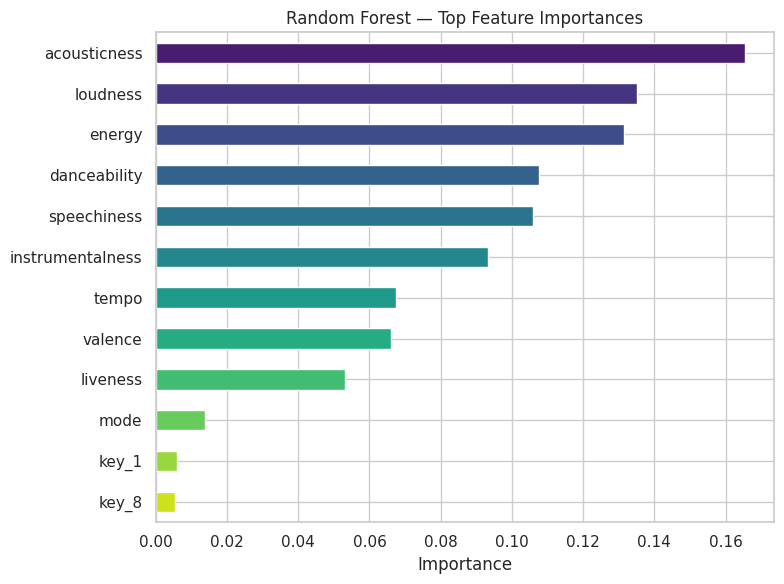

In [17]:
rf = trained_models["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8,6))
importances.head(12).plot(kind="barh", color=sns.color_palette("viridis", 12))
plt.gca().invert_yaxis()
plt.title("Random Forest — Top Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


## 11. Conclusion & Discussion

### Actual results from this run

| Rank | Model | Test Accuracy | 5-fold CV Accuracy (mean ± std) |
|---|---|---|---|
| 1 | **Random Forest** | **0.638** | 0.618 ± 0.017 |
| 2 | SVM (RBF) | 0.607 | 0.603 ± 0.008 |
| 3 | Logistic Regression | 0.568 | 0.588 ± 0.010 |
| 3 | KNN | 0.568 | 0.545 ± 0.013 |
| 5 | Decision Tree | 0.534 | 0.541 ± 0.014 |
| 6 | Naive Bayes | 0.524 | 0.531 ± 0.021 |

The test-set accuracy and the 5-fold CV mean agree closely for every model (all within ~0.02 of
each other), which means the single train/test split wasn't a lucky or unlucky draw — the ranking
above is stable, not noise.

### Why each model lands where it does

- **Random Forest wins**, as expected on real, non-synthetic tabular audio data: genre is not a
  linear function of these 9 features (e.g. "energetic but not danceable" can mean Rock *or*
  the more aggressive end of EDM), and an ensemble of trees captures that kind of conditional,
  non-linear interaction far better than a single boundary.
- **SVM (RBF) is a close second** — the kernel trick gives it a similar non-linear advantage
  without the variance of a single Decision Tree, but it can't match Random Forest's ability to
  automatically weight the most informative features.
- **Logistic Regression and KNN tie** — Logistic Regression works because several features
  (acousticness, loudness) are individually strong, near-linear separators for genres like
  Classical; KNN works reasonably well because those same genres form fairly compact,
  separable local neighborhoods, but it degrades faster wherever classes overlap.
- **Decision Tree underperforms Random Forest by ~10 points** — a single tree overfits the
  specific splits it finds in the training data and doesn't generalize as cleanly; this is
  exactly the gap Random Forest exists to close.
- **Naive Bayes finishes last** — its core assumption (each feature is conditionally independent
  and Gaussian given the genre) is simply false for real audio features: energy, loudness, and
  acousticness are strongly correlated (see the heatmap in Section 3), and Naive Bayes can't use
  that correlation structure at all.

### The real story is in the classification report, not just accuracy

Random Forest's per-class breakdown tells a much more useful story than the single 0.64 number:

| Genre | Precision | Recall | F1 |
|---|---|---|---|
| Classical | 0.97 | 0.89 | 0.93 |
| Rock | 0.65 | 0.61 | 0.63 |
| EDM | 0.58 | 0.64 | 0.61 |
| Hip-Hop | 0.53 | 0.58 | 0.55 |
| **Pop** | **0.48** | **0.46** | **0.47** |

- **Classical separates almost perfectly** — it's acoustically the outlier of the five (high
  acousticness, low energy, low loudness), so every model finds it easily. This single genre is
  doing a lot of the work in the overall accuracy number.
- **Pop is the clear weak point**, by a wide margin. This isn't a bug in the code — it's a
  genuine property of the genre itself: "Pop" as a Spotify tag describes a *commercial/production
  style*, not a consistent *sound*. Pop songs routinely borrow the danceability of EDM, the
  loudness of Rock, or the vocal delivery of Hip-Hop, so its audio-feature fingerprint legitimately
  overlaps all three. No amount of tuning on these 11 features alone will fully fix this — it
  would need additional signal the dataset doesn't have (e.g. lyrics, vocal timbre, release year).
- **Rock, EDM, and Hip-Hop sit in the middle**, each confused mostly with their nearest acoustic
  neighbor (visible in the Section 7 confusion matrices) rather than with Classical.

### What actually drives the prediction (Random Forest feature importances)

1. `acousticness` (16.6%)
2. `loudness` (13.5%)
3. `energy` (13.2%)
4. `danceability` (10.7%)
5. `speechiness` (10.6%)
6. `instrumentalness` (9.3%)

`tempo` and `valence` matter, but noticeably less. The one-hot `key` columns and `mode` contribute
almost nothing individually — musical key correlates with genre far more weakly than the
production-related features do, which is exactly what we'd expect (key is an artistic choice,
not a genre signature).

### Honest limits of this comparison

- 64% accuracy on 5 balanced classes (baseline = 20%) shows the model is learning real structure,
  but it's not production-grade — genre tagging from 11 audio features alone has a ceiling, mostly
  because of Pop's inherent overlap with everything else.
- This is a 5-genre subset chosen because it's sonically distinct. Repeating this on closer genres
  (e.g. `pop` vs `indie-pop` vs `dance`) would show every model's accuracy drop further and would
  be a more honest stress test if this becomes a portfolio piece.
- With `class_weight="balanced"` in place, we kept 3,635 rows for training/testing here instead of
  undersampling every class down to Rock's 609 — real data preserved, no synthetic upsampling used.
